# 04 · Ablación de orientación y comparación de resolución
Los controles emparejados de DBSCAN y HDBSCAN100 cambian **solo orientation=True/False**, conservando RANSAC corregido, voxel, eps, min_samples y crecimiento por distancia. Ambos brazos ejecutan las mismas dos fusiones, infiriendo los ejes por PCA de instancia con el mismo criterio. También comparten el crecimiento y clustering del residuo; solo cambia la partición inicial por orientación. Incluimos también un control sin fusión para distinguir ese efecto. No reutilizamos la antigua separación especial de fustes.

Reportamos silhouette_comun/DB_comun como diagnóstico histórico, con K explícito, sin usarlos para afirmar mejora. La evaluación geométrica usa xyz+normales+linealidad estandarizados una sola vez y segmentos con ≥500 puntos **de la nube completa**. Cada pipeline y clase se evalúan en el mismo soporte pareado de esos segmentos; reportamos la cobertura para no premiar descarte. El filtro de tamaño no corrige por sí solo el sesgo por K: añadimos una agregación a K=11 de los centroides de segmentos (k-means ponderado, seed=0), conservando cada segmento completo. No se interpreta esa agregación como instancias físicas.

ARI y NMI comparan la partición colapsada a clases heurísticas con los once grupos de clase: son concordancia, no calidad, y no esperamos que sean altos al corregir el piso. El ruido permanece como clase en esa referencia. Por separado, ARI_media/std mide estabilidad entre tres réplicas de voxel y remuestreo, no concordancia con clase.

La selección usa la enmienda visual documentada en 00: se cuentan huellas altas distintas (centros xy agrupados a 1.5 m), no caras duplicadas. Esto no modifica las etiquetas. La regla de selección de 00 prioriza las metas geométricas y menor fragmentación total; nunca silhouette entre K distintos. Usamos el número total de segmentos para seleccionar, no solo los ≥500: de otro modo se premiaría esconder fragmentos bajo el filtro de evaluación. Las métricas de piso usan el mismo soporte de etapa 1 para todas las configuraciones. Los segundos suman ajuste nominal y tres réplicas, excluyendo evaluación y figuras.

**Ejecución:** IPython en `.venv`, celdas en orden, sin kernel de sockets (nbconvert bloqueado por sandbox). Tiempo: 257.61 s. Logs en `outputs/logs/`; cachés en `outputs/cache/`.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.dont_write_bytecode = True
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0,str(ROOT/'src'))
os.environ['MPLCONFIGDIR']=str(ROOT/'outputs/cache/exp_matplotlib')
os.environ['IPYTHONDIR']=str(ROOT/'outputs/cache/exp_ipython')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, build_features
from pcseg.metrics import silhouette_sample, davies_bouldin
from pcseg.stages import *
plt.switch_backend('Agg')
thread_limit = threadpool_limits(limits=2)
OUT=ROOT/'outputs'; CACHE=OUT/'cache'; FIG=OUT/'figs'; LOG=OUT/'logs'; ENT=ROOT/'entregable'; ENT.mkdir(exist_ok=True)
START=time.perf_counter()
cloud=read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
common_idx=np.load(OUT/'sample_idx.npy')
xyz,rgb,normals=(cloud[k][common_idx] for k in ('xyz','rgb','normals'))
EVAL=build_features(xyz,rgb,normals,use_rgb=True,use_normals=True,use_height=True)
base_table=pd.read_csv(ENT/'clase_metricas.csv')
base=base_table[base_table.seleccionada].iloc[0]
base_labels=np.load(LOG/'clase_labels'/f'{base.id}.npy')
assert len(xyz)==93903 and len(cloud['xyz'])==1647021
print('Muestra común',len(xyz),'Python',sys.executable,sys.version.split()[0])
CLASS_COLORS={'piso':(70,155,70),'techo':(90,140,230),'pared':(190,145,90),
 'plano_horizontal':(145,190,220),'columna':(230,60,55),'viga_horizontal':(245,170,35),
 'viga_o_tuberia':(225,125,25),'tuberia':(25,180,185),
 'equipo_bajo':(155,75,190),'compacto_plausible':(30,200,190),
 'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45)}
def view(points,labels,name,title,classes=None):
    idx=np.random.default_rng(0).choice(len(points),min(35000,len(points)),replace=False)
    p=points[idx]; ls=labels[idx]
    if classes is None: colors=labels_to_rgb(ls)/255.
    else: colors=np.array([CLASS_COLORS[classes[int(v)]] for v in ls])/255.
    fig=plt.figure(figsize=(16,5))
    for i,j in enumerate((1,2)):
        ax=fig.add_subplot(1,3,i+1)
        ax.scatter(p[:,0],p[:,j],c=colors,s=2,alpha=.65,linewidths=0)
        ax.set(xlabel='x (m)',ylabel='y (m)' if j==1 else 'z (m)',aspect='equal',title='Superior' if j==1 else 'Lateral')
    ax=fig.add_subplot(1,3,3,projection='3d'); ax.scatter(*p.T,c=colors,s=1,alpha=.65)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D'); ax.set_box_aspect(np.maximum(np.ptp(p,axis=0),.1))
    if classes:
        names=sorted(set(classes.values()))
        fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255,label=n) for n in names],loc='lower center',ncol=4,fontsize=8)
    fig.suptitle(title); fig.tight_layout(rect=(0,.12,1,.94) if classes else (0,0,1,.94))
    path=FIG/f'exp_{name}.png'; fig.savefig(path,dpi=140); plt.close(fig); display(Image(filename=str(path)))
def save_run(name,run):
    np.savez_compressed(CACHE/f'exp_{name}.npz',labels=run['labels'],idx=run['idx'],sample_labels=run['sample_labels'])
    serial=[]
    for p in run['planes']:
        serial.append({k:v for k,v in p.items() if k!='inliers'})
    (CACHE/f'exp_{name}_planes.json').write_text(json.dumps(serial,indent=2))
    supports={f'plano_{j}':run['idx'][p['inliers']] for j,p in enumerate(run['planes'])}
    sampled=cloud['xyz'][run['idx']]
    for j,p in enumerate(run['planes']):
        for k,coef in enumerate(p.get('patches',[])):
            mask=np.abs(sampled@np.asarray(coef[:3])+coef[3])<.08
            supports[f'plano_{j}_parche_{k}']=run['idx'][mask]
    np.savez_compressed(CACHE/f'exp_{name}_inliers.npz',**supports)
def load_run(name):
    a=dict(np.load(CACHE/f'exp_{name}.npz'))
    a['planes']=json.loads((CACHE/f'exp_{name}_planes.json').read_text())
    return a
def finish(name, payload):
    payload['segundos_notebook']=time.perf_counter()-START
    (CACHE/f'exp_resumen_{name}.json').write_text(json.dumps(payload,indent=2,default=float))
    print(payload)

from pcseg.propagate import propagate_labels
from sklearn.preprocessing import StandardScaler
BASE_FULL=propagate_labels(xyz,base_labels,cloud['xyz'])
def maps_and_totals(run):
    desc,totals=summarize_classes(cloud['xyz'],run['labels'],run['planes'])
    classes=dict(zip(desc.id,desc.clase_heuristica)); classes[-1]='ruido'
    return desc,totals,classes
def mixture_metrics(desc,totals):
    def pct(name):
        row=totals[totals.clase_heuristica==name]
        return float(row.porcentaje.sum())
    columns=desc[desc.clase_heuristica=='columna']
    high=columns[columns.extension_vertical>=5]
    from sklearn.cluster import DBSCAN
    xy=(high[['x_min','y_min']].to_numpy()+high[['x_max','y_max']].to_numpy())/2
    footprints=DBSCAN(eps=1.5,min_samples=1).fit_predict(xy) if len(high) else []
    distinct=len(set(footprints))
    return dict(n_segmentos_completo=int((desc.id>=0).sum()),mezcla_pct=pct('mezcla_no_identificada'),ruido_completo_pct=pct('ruido'),
        no_resuelto_pct=pct('mezcla_no_identificada')+pct('ruido'),
        n_columnas=int(len(columns)),n_columnas_altas=int((columns.extension_vertical>=5).sum()),n_columnas_altas_distintas=distinct)
def geometry_space():
    path=CACHE/'exp_features_geo.npy'
    if path.exists(): return np.load(path)
    f=local_pca_features(xyz,k=96)
    X=StandardScaler().fit_transform(np.c_[xyz,normals,f['linealidad']])
    np.save(path,X)
    return X


Muestra común 93903 Python /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


orientacion mezcla 7.58 columnas 38 altas 18 K500 265 ARI 0.969


sin_orientacion mezcla 61.14 columnas 4 altas 1 K500 17 ARI 0.966


sin_fusion mezcla 10.14 columnas 48 altas 13 K500 472 ARI 0.982


sin_normales mezcla 7.63 columnas 38 altas 17 K500 274 ARI 0.554


con_color mezcla 7.58 columnas 38 altas 18 K500 267 ARI 0.969


con_height mezcla 7.15 columnas 40 altas 17 K500 264 ARI 0.968


... (8 outputs left out)

k48 mezcla 9.52 columnas 35 altas 16 K500 242 ARI 0.967


crecer025 mezcla 9.69 columnas 37 altas 16 K500 259 ARI 0.966


,configuracion,n_segmentos,n_segmentos_500,mezcla_pct,ruido_completo_pct,n_columnas,n_columnas_altas,n_columnas_altas_distintas,silhouette_geo,DB_geo,silhouette_geo_K11,DB_geo_K11,ARI_media
0,linea_base_clase,11,11,NaN,0.000000,NaN,NaN,NaN,0.154465,2.564751,0.154465,2.564751,0.952452
1,orientacion,664,265,7.578956,0.422338,38.0,18.0,16.0,-0.323802,4.363660,0.105657,2.687358,0.968776
2,sin_orientacion,106,17,61.137350,0.135396,4.0,1.0,1.0,-0.259376,2.329595,-0.088040,1.999219,0.966133
3,sin_fusion,1233,472,10.139094,0.422338,48.0,13.0,10.0,-0.371312,4.149898,0.135560,2.346046,0.981572
4,sin_normales,708,274,7.629654,0.356947,38.0,17.0,16.0,-0.316072,4.139180,0.052555,2.518052,0.554401
5,con_color,667,267,7.578956,0.422338,38.0,18.0,16.0,-0.290141,4.389416,0.130274,2.666050,0.968791
6,con_height,672,264,7.150486,0.440796,40.0,17.0,16.0,-0.272821,4.397519,0.100150,2.689377,0.967597
7,voxel010,756,225,10.245892,0.139828,43.0,18.0,16.0,-0.305648,4.266179,0.129790,2.668400,0.872532
8,voxel025,590,322,8.997578,2.502700,23.0,18.0,16.0,-0.366134,4.188280,0.128753,2.482830,0.859765
9,eps025,744,277,6.688621,0.927675,35.0,19.0,18.0,-0.307803,4.489131,0.122754,2.502243,0.959026


Selección: {'configuracion': 'HDBSCAN40', 'parametros': {'eps': 0.35, 'k': 96, 'linear_threshold': 0.45, 'merge_gap': 1.2, 'merge_lateral': 0.75, 'method': 'hdbscan', 'min_cluster_size': 40, 'min_samples': 6, 'planar_threshold': 0.5, 'reassign_distance': 0.45, 'voxel': 0.15}, 'etapa': 'metas_cumplidas', 'candidatos': 10}


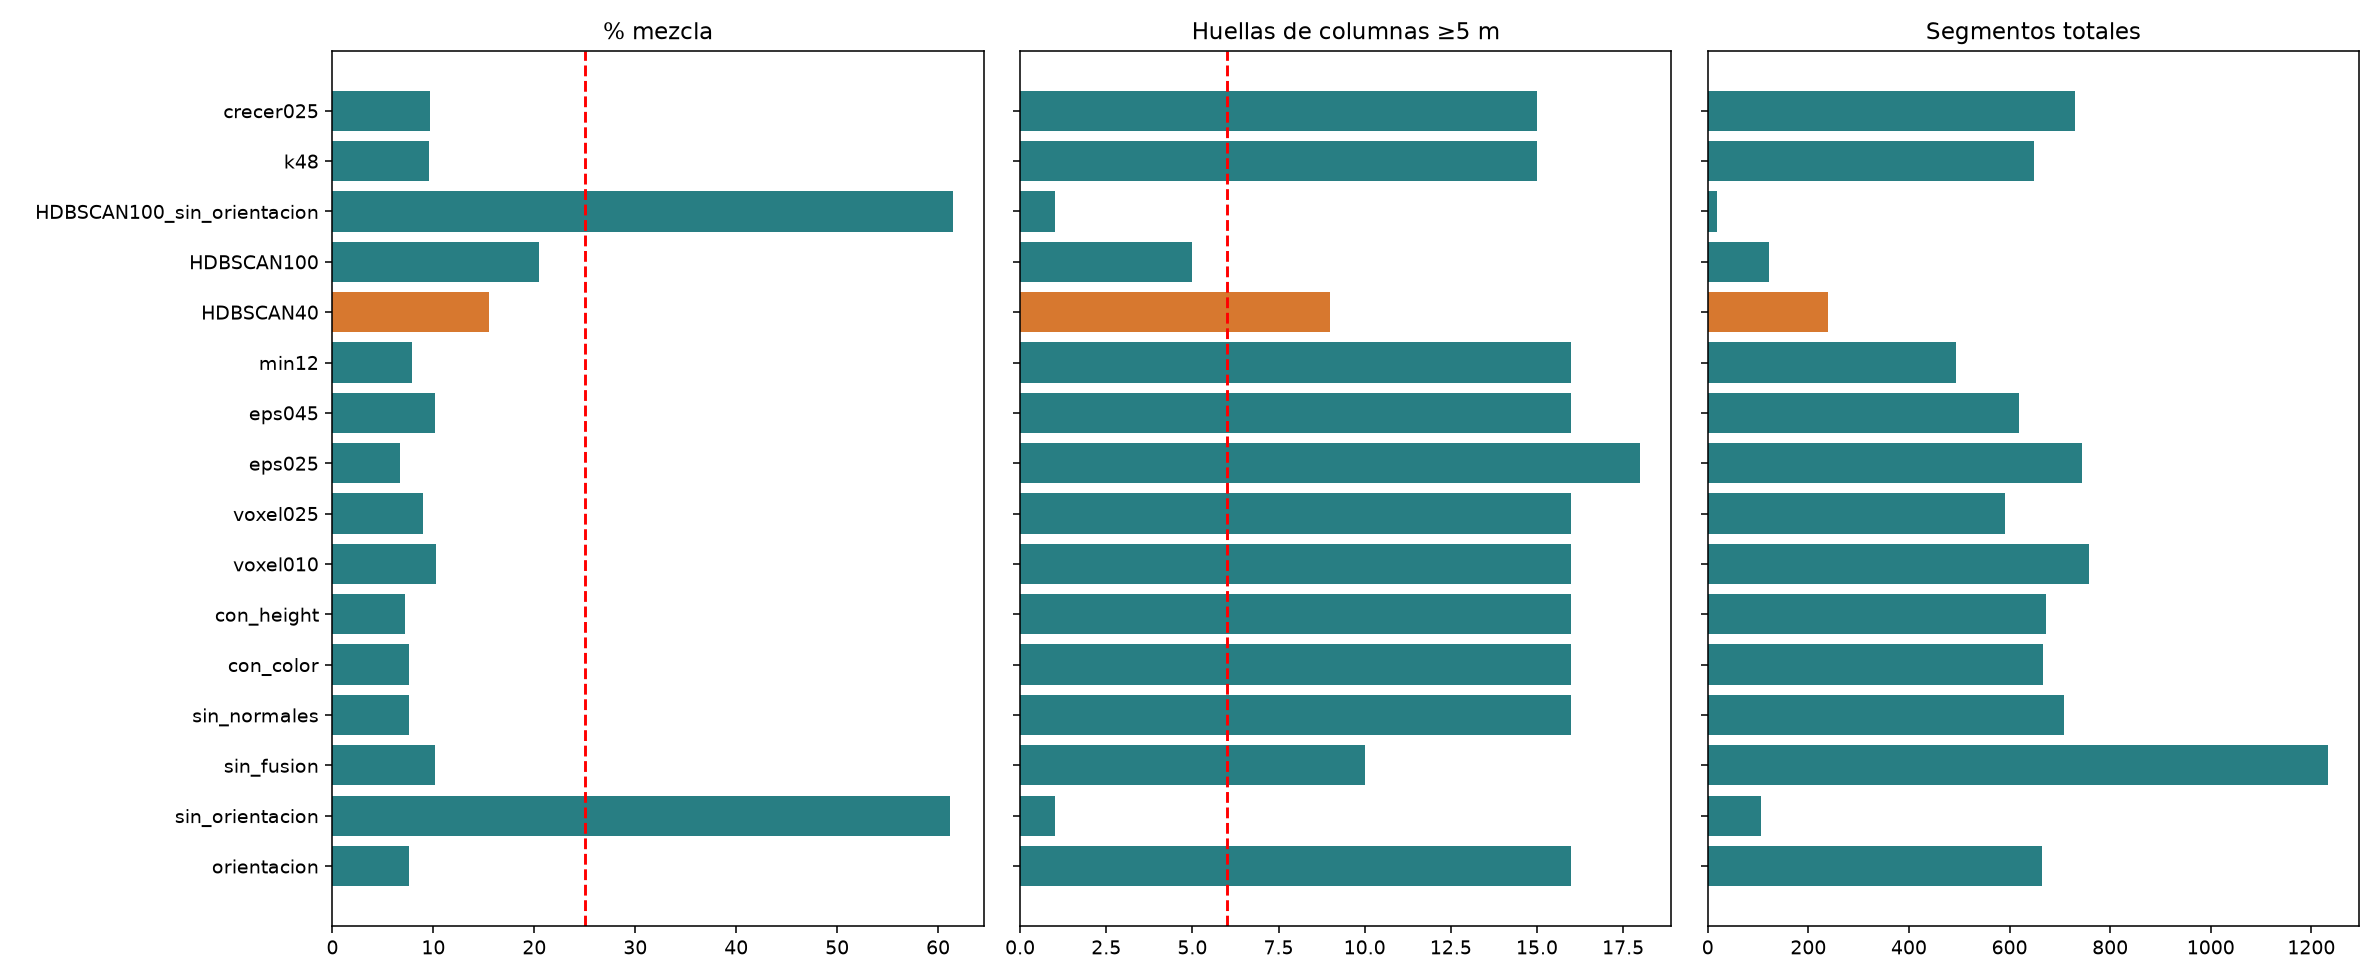

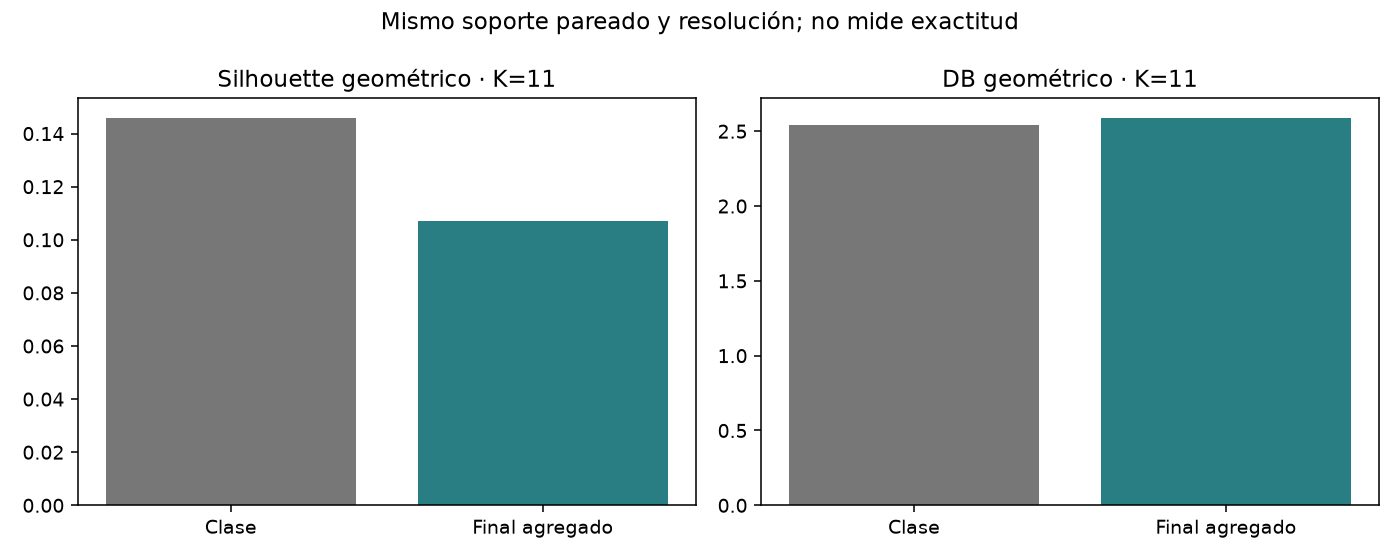

{'configuracion': 'HDBSCAN40', 'parametros': {'eps': 0.35, 'k': 96, 'linear_threshold': 0.45, 'merge_gap': 1.2, 'merge_lateral': 0.75, 'method': 'hdbscan', 'min_cluster_size': 40, 'min_samples': 6, 'planar_threshold': 0.5, 'reassign_distance': 0.45, 'voxel': 0.15}, 'etapa': 'metas_cumplidas', 'candidatos': 10, 'segundos_notebook': 279.7157463270014}


In [2]:
reference=json.loads((CACHE/'exp_config_referencia.json').read_text());structure=load_run('estructura');reference_planes=structure['planes']
XGEO=geometry_space()
changes=[('orientacion',{}),('sin_orientacion',{'orientation':False}),('sin_fusion',{'merge_gap':0.,'merge_lateral':0.}),
 ('sin_normales',{'normals':False}),('con_color',{'color':True}),('con_height',{'height':True}),
 ('voxel010',{'voxel':.10}),('voxel025',{'voxel':.25}),('eps025',{'eps':.25}),('eps045',{'eps':.45}),
 ('min12',{'min_samples':12}),('HDBSCAN40',{'method':'hdbscan','min_cluster_size':40}),
 ('HDBSCAN100',{'method':'hdbscan','min_cluster_size':100,'min_samples':12}),
 ('HDBSCAN100_sin_orientacion',{'method':'hdbscan','min_cluster_size':100,'min_samples':12,'orientation':False}),('k48',{'k':48}),('crecer025',{'reassign_distance':.25})]
rows=[];replica_rows=[]
basemetrics=evaluate(EVAL,xyz,base_labels,reference_planes)
basegeo=geometric_comparison(XGEO,BASE_FULL,common_idx,BASE_FULL)
rows.append(dict(configuracion='linea_base_clase',**basemetrics,**basegeo,ARI_media=float(base.ARI),ARI_std=float(base.ARI_std),
    protocolo_ARI='semillas_histórico',segundos=0.,mezcla_pct=np.nan,ruido_completo_pct=0.,no_resuelto_pct=np.nan,n_columnas=np.nan,n_columnas_altas=np.nan,n_columnas_altas_distintas=np.nan,parametros='k-means K=11 original'))
for name,change in changes:
    params=dict(reference);params.update(change)
    run=pipeline(cloud,cloud['xyz'],**params);save_run(name,run)
    desc,totals,classes=maps_and_totals(run)
    desc.to_csv(CACHE/f'exp_descriptores_{name}.csv',index=False)
    totals.to_csv(CACHE/f'exp_clases_{name}.csv',index=False)
    common_labels=run['labels'][common_idx]
    metrics=evaluate(EVAL,xyz,common_labels,run['planes'])
    floor=floor_metrics(xyz,common_labels,reference_planes)
    metrics['%piso_en_un_segmento']=floor['piso_en_un_segmento'];metrics['piso_n_segmentos']=floor['piso_n_segmentos']
    geo=geometric_comparison(XGEO,run['labels'],common_idx,BASE_FULL,classes)
    replicas=[];seconds=run['seconds']
    for scale in (.9,1.,1.1):
        options=dict(params);options['voxel']=params['voxel']*scale
        rr=pipeline(cloud,xyz,**options,subsample=True);seconds+=rr['seconds'];replicas.append(rr['labels'])
        np.save(CACHE/f'exp_estabilidad_{name}_{scale}.npy',rr['labels'])
        replica_rows.append(dict(configuracion=name,voxel=options['voxel'],n_ajuste=len(rr['idx']),segundos=rr['seconds'],
            **floor_metrics(xyz,rr['labels'],reference_planes)))
    ari,std=stability(replicas)
    nonplan=assign_planes(xyz,reference_planes,.08)<0
    ari_res,std_res=stability([labels[nonplan] for labels in replicas])
    row=dict(configuracion=name,**metrics,**geo,**mixture_metrics(desc,totals),ARI_media=ari,ARI_std=std,
        ARI_residuo=ari_res,ARI_residuo_std=std_res,protocolo_ARI='remuestreo_voxel',segundos=seconds,parametros=json.dumps(params,sort_keys=True))
    rows.append(row)
    pd.DataFrame(rows).to_csv(ENT/'exp_ablaciones.csv',index=False)
    print(name,'mezcla',round(row['mezcla_pct'],2),'columnas',row['n_columnas'],'altas',row['n_columnas_altas'],
        'K500',row['n_segmentos_500'],'ARI',round(ari,3),flush=True)
abl=pd.DataFrame(rows);abl.to_csv(ENT/'exp_ablaciones.csv',index=False)
pd.DataFrame(replica_rows).to_csv(OUT/'exp_estabilidad_replicas.csv',index=False)
valid=abl[abl.configuracion!='linea_base_clase'].copy()
mask=(valid['%piso_en_un_segmento']>=95)&(valid.mezcla_pct<25)&(valid.no_resuelto_pct<25)&(valid.ruido_completo_pct<=5)&(valid.n_columnas>=6)&(valid.n_columnas_altas_distintas>=6)
valid['cumple_metas']=mask
if mask.any():
    eligible=valid[mask].sort_values(['n_segmentos_completo','mezcla_pct','ARI_media','configuracion'],ascending=[True,True,False,True]);stage='metas_cumplidas'
else:
    eligible=valid.sort_values(['no_resuelto_pct','configuracion']);stage='meta_fallida'
best_exp=eligible.iloc[0];valid['seleccionada']=valid.configuracion==best_exp.configuracion
valid.to_csv(OUT/'exp_ranking.csv',index=False)
selection=dict(configuracion=best_exp.configuracion,parametros=json.loads(best_exp.parametros),etapa=stage,candidatos=int(mask.sum()))
(CACHE/'exp_mejor_config.json').write_text(json.dumps(selection,indent=2))
display(abl[['configuracion','n_segmentos','n_segmentos_500','mezcla_pct','ruido_completo_pct','n_columnas','n_columnas_altas','n_columnas_altas_distintas','silhouette_geo','DB_geo','silhouette_geo_K11','DB_geo_K11','ARI_media']])
print('Selección:',selection)
# Tabla de resolución comparable, con soporte y concordancia explícitos.
fcols=['configuracion','n_segmentos_500','cobertura_500_pct','n_soporte_pareado','mayor_segmento_pct','silhouette_geo','DB_geo','silhouette_base_pareado','DB_base_pareado','n_geo_K11','silhouette_geo_K11','DB_geo_K11','ARI_clases_base','NMI_clases_base']
abl[fcols].to_csv(ENT/'exp_comparacion_justa.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(17,7));y=np.arange(len(valid))
for ax,col,title in zip(axes,['mezcla_pct','n_columnas_altas_distintas','n_segmentos_completo'],['% mezcla','Huellas de columnas ≥5 m','Segmentos totales']):
    ax.barh(y,valid[col],color=['#287e83' if value!=best_exp.configuracion else '#d7782f' for value in valid.configuracion]);ax.set(yticks=y,yticklabels=valid.configuracion if ax is axes[0] else [],title=title)
axes[0].axvline(25,c='r',ls='--');axes[1].axvline(6,c='r',ls='--')
path=FIG/'exp_04_resumen.png';fig.tight_layout();fig.savefig(path,dpi=140);plt.close(fig);display(Image(filename=str(path)))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,base_col,new_col,title in zip(axes,['silhouette_base_pareado','DB_base_pareado'],['silhouette_geo_K11','DB_geo_K11'],['Silhouette geométrico · K=11','DB geométrico · K=11']):
    ax.bar(['Clase','Final agregado'],[best_exp[base_col],best_exp[new_col]],color=['#777777','#287e83']);ax.set(title=title)
fig.suptitle('Mismo soporte pareado y resolución; no mide exactitud');fig.tight_layout()
path=FIG/'exp_04_comparacion_K11.png';fig.savefig(path,dpi=140);plt.close(fig);display(Image(filename=str(path)))
finish('04',selection)

## Qué aprendimos / qué falló
El cambio de orientación tiene un efecto grande incluso manteniendo el resto: DBSCAN pasa de **61.14% de mezcla sin orientación a 7.58% con ella**. HDBSCAN100 pasa de **61.44% a 20.47%**. No es una medida de exactitud: son porcentajes bajo las mismas reglas geométricas, acompañados por las vistas. El ruido completo permanece bajo; no estamos escondiendo la mezcla como ruido.

La selección inicial por cantidad de segmentos habría elegido HDBSCAN100. Al revisar su panel, sus seis etiquetas altas eran **cinco huellas** y faltaban columnas claras cerca de x≈3.5 y 13.5. Documentamos esa corrección de selección en 00: exigimos seis huellas altas separadas, agrupando centros xy a 1.5 m solo para auditar el conteo. **No presentamos esa enmienda como una regla fijada antes de la primera corrida.** Tras ella, gana **HDBSCAN40**: **239 segmentos**, mezcla **15.55%**, ruido **0.55%**, 17 candidatas a columna y 11 altas en nueve huellas. Se sacrifica la mezcla menor de DBSCAN para reducir la fragmentación de 664 a 239 segmentos; no se exige que todas sean objetos reales.

Con el mismo soporte de **91 981 puntos**, features geométricas fijas y resolución K=11, clase obtiene silhouette **0.1459** y DB **2.5439**, y el final agregado **0.1070** y **2.5894**. **No superamos a clase en esa comparación controlada.** Sin agregar, el final tiene 218 segmentos grandes y sus métricas no deben compararse como si fueran K=11. ARI/NMI entre clases colapsadas y la base son **0.1662/0.2637**, solo concordancia. ARI de remuestreo del ganador es **0.9672±0.0025**; no es comparable directamente con el histórico entre semillas de clase (0.9525).